# Hyperparameter tuning for imputation and forecasting

This notebook tunes every imputation and forecasting algorithm before comparing them, so each algorithm is compared at its best settings rather than at hand picked ones. It reuses the data preparation from `nasipadang.ipynb` and does not change that notebook.

Rules that apply to every algorithm:

| Rule | Why |
|---|---|
| Every algorithm is tuned with a full grid search over a grid of similar size | A much bigger search would give an algorithm an unfair advantage |
| Tuning only uses data that the final score never sees | Tuning on the test data would make the test meaningless |
| The final score is computed once, after tuning is finished | So the reported error is an honest estimate |
| The chosen settings are printed | So the reader can check what each algorithm was tuned to |

In [1]:
import os
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from adjustText import adjust_text
from joblib import Parallel, delayed
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GridSearchCV, KFold, ParameterGrid
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

os.environ["PYTHONWARNINGS"] = "ignore"  # also silences the parallel workers used in section 7
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*xlrd engine is deprecated.*")

DATA = Path("data/climate_change.xls")
FIG_DIR = Path("figures_tuning")
FIG_DIR.mkdir(exist_ok=True)
SEED = 42

# Categorical slots in fixed order, plus chart chrome
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#104281", "#3987e5", "#f0efec", "#e66767", "#a12a2a"])
GOOD_BAD = DIV.reversed()  # blue = good for the shop, red = bad

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})


def titled(ax, title, subtitle=None):
    """Bold left aligned title with an optional muted subtitle underneath."""
    ax.set_title(title, pad=24 if subtitle else 8)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 7), textcoords="offset points",
                    fontsize=9, color=INK_2, va="bottom")


def label_points(ax, xs, ys, labels, colors=None):
    """Direct labels nudged apart so they never overlap each other or the points."""
    weight = "normal" if colors is None else "bold"
    colors = [INK] * len(labels) if colors is None else colors
    texts = [ax.text(x, y, t, fontsize=8, color=colour, fontweight=weight, bbox={"facecolor": SURFACE, "edgecolor": "none", "alpha": 0.75, "pad": 1.5})
             for x, y, t, colour in zip(xs, ys, labels, colors)]
    adjust_text(texts, x=list(xs), y=list(ys), ax=ax, expand=(1.3, 1.8),
                arrowprops={"arrowstyle": "-", "color": AXIS, "lw": 0.6})


def save(fig, name):
    """Save a slide ready figure with a source footnote placed below everything else."""
    fig.canvas.draw()
    bottom = fig.get_tightbbox(fig.canvas.get_renderer()).y0 / fig.get_figheight()
    # fig.text(0.01, bottom - 0.01, "Source: World Bank climate change data (MA0218 course dataset)",
    #          fontsize=7, color=MUTED, va="top")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()
N_JOBS = -1

## Load and prepare the data

The same steps as in `nasipadang.ipynb`: reshape the workbook, build the features, fill rule based blanks, drop countries missing more than 40% of inputs, then log transform and standardise.

In [2]:
raw = pd.read_excel(DATA, sheet_name="Data")
meta = pd.read_excel(DATA, sheet_name="Country")
meta = meta[meta["Region"] != "Aggregates"].set_index("Country code")
raw = raw[raw["Country code"].isin(meta.index)]

YEARS = [c for c in raw.columns if str(c).isdigit()]
wide = raw.set_index(["Country code", "Series name"])[YEARS].replace("..", np.nan)
names = meta["Country name"]

print(f"{len(meta)} countries x {raw['Series name'].nunique()} features x {len(YEARS)} years "
      f"({YEARS[0]}-{YEARS[-1]})")

def ts(name):
    """Country x year table of a numeric feature."""
    return wide.xs(name, level="Series name").apply(pd.to_numeric, errors="coerce")


def latest(name):
    """Most recent reported value per country."""
    return ts(name).ffill(axis=1).iloc[:, -1]


def text(name):
    """Most recent raw (text) value per country, for snapshot features stored as strings."""
    return wide.xs(name, level="Series name").ffill(axis=1).iloc[:, -1]


def midpoint(name, sep):
    """Parse 'a to b' or 'a / b' strings and return the midpoint."""
    parts = text(name).astype("string").str.extract(rf"(-?[\d.]+)\s*{sep}\s*(-?[\d.]+)").astype(float)
    return parts.mean(axis=1)

218 countries x 58 features x 22 years (1990-2011)


In [3]:
f = pd.DataFrame(index=meta.index)

# Demand
f["population"] = latest("Population")
f["urban_pop"] = latest("Urban population")
f["gni_pc"] = latest("GNI per capita (Atlas $)")

# Supply: methane per person (methane is only reported for 1990/1995/2000/2005, so use 2005)
f["methane_pc"] = ts("Methane (CH4) emissions, total (KtCO2e)")[2005] * 1000 / ts("Population")[2005]

# Supply: cereal yield trend (% per year) and volatility (std of year on year % change), needs >= 10 years
log_yield = np.log(ts("Cereal yield (kg per hectare)"))
year_num = np.array([int(y) for y in log_yield.columns])


def trend(row):
    ok = row.notna().values
    return np.polyfit(year_num[ok], row.values[ok], 1)[0] * 100 if ok.sum() >= 10 else np.nan


enough = log_yield.notna().sum(axis=1) >= 10
f["yield_trend"] = log_yield.apply(trend, axis=1)
f["yield_volatility"] = (log_yield.diff(axis=1).std(axis=1) * 100).where(enough)

# Climate: relative rainfall shift and absolute temperature, estimated for 2030 by steady change from 1975 to 2055
CLIMATE_SHARE = (2030 - 1975) / (2055 - 1975)
f["rain_shift"] = (CLIMATE_SHARE * midpoint("Projected annual precipitation change (2045-2065, mm)", "to")
                   / latest("Average annual precipitation (1961-1990, mm)"))
f["temp_2030"] = (midpoint("Average daily min/max temperature (1961-1990, Celsius)", "/")
                  + CLIMATE_SHARE * midpoint("Projected annual temperature change (2045-2065, Celsius)", "to"))

# Kitchen and operations
f["electricity"] = latest("Access to electricity (% of total population)")
f["paved_roads"] = latest("Paved roads (% of total roads)")
f["water"] = latest("Access to improved water source (% of total pop.)")
f["sanitation"] = latest("Access to improved sanitation (% of total pop.)")
f["physicians"] = latest("Physicians (per 1,000 people)")
f["nurses"] = latest("Nurses and midwives (per 1,000 people)")
f["malaria"] = latest("Malaria incidence rate (per 100,000 people)")
f["ease_rank"] = latest("Ease of doing business (ranking 1-183; 1=best)")

# Helpers for imputation only (well covered development features)
f["co2_pc"] = latest("CO2 emissions per capita (metric tons)")
f["u5_mortality"] = latest("Under-five mortality rate (per 1,000)")

# Climate commitments (text flags)
f["annex1_target"] = text("Annex-I emissions reduction target").notna().astype(int)
f["renewable_target"] = text("Renewable energy target").notna().astype(int)
f["nama"] = text("NAMA submission").notna().astype(int)
f["unfccc_reports"] = (text("Latest UNFCCC national communication").astype("string")
                       .str.extract(r"\((\d)")[0].astype(float))

rich = meta["Income group"].str.startswith("High income")
before = f["electricity"].isna().sum()
f.loc[rich & f["electricity"].isna(), "electricity"] = 100.0
f["malaria"] = f["malaria"].fillna(0.0)
f["unfccc_reports"] = f["unfccc_reports"].fillna(0.0)
print(f"Electricity: {before} blanks -> {f['electricity'].isna().sum()} after filling high income countries at 100%")
print("Malaria and commitment blanks filled with 0")

IMPUTE = ["urban_pop", "gni_pc", "methane_pc", "co2_pc", "u5_mortality", "yield_trend", "yield_volatility",
          "rain_shift", "temp_2030", "electricity", "paved_roads", "water", "sanitation", "physicians", "nurses",
          "ease_rank"]
LOG = ["urban_pop", "gni_pc", "methane_pc", "co2_pc", "u5_mortality", "physicians", "nurses"]

X = f[IMPUTE].copy()
X[LOG] = np.log(X[LOG])
observed_share = X.notna().mean(axis=1)
dropped = names[observed_share < 0.6]
X = X[observed_share >= 0.6]
print(f"Kept {len(X)} countries, dropped {len(dropped)}: {', '.join(dropped)}")
print(f"Blanks left to impute: {int(X.isna().sum().sum())} of {X.size} values ({X.isna().mean().mean():.1%})")

scaler = StandardScaler()
Z = pd.DataFrame(scaler.fit_transform(X), index=X.index, columns=X.columns)

Electricity: 131 blanks -> 71 after filling high income countries at 100%
Malaria and commitment blanks filled with 0
Kept 190 countries, dropped 28: Aruba, American Samoa, Bermuda, Channel Islands, Cook Islands, Curacao, Cayman Islands, Faeroe Islands, Gibraltar, Greenland, Guam, Isle of Man, Kosovo, Liechtenstein, Macao SAR, China, St. Martin (French part), Montenegro, Northern Mariana Islands, Mayotte, New Caledonia, Niue, Nauru, French Polynesia, San Marino, Sint Maarten (Dutch part), Turks and Caicos Islands, Tuvalu, Virgin Islands (U.S.)
Blanks left to impute: 207 of 3040 values (6.8%)


## Imputation

Each imputer is tuned on three tuning masks (seeds 200 to 202), each hiding 15% of the known values. The tuned settings are then scored on the five test masks used in `nasipadang.ipynb` (seeds 100 to 104), which tuning never sees. Every imputer tries all 12 settings in its grid (a grid search, with the tuning masks acting as the validation set). The column mean has no settings to tune.

In [4]:
def autoencoder_impute(Zm, hidden=64, latent=8, drop=0.3, weight_decay=1e-3, epochs=1500, n_models=5, seed=SEED):
    """Denoising autoencoder imputer, as in nasipadang.ipynb, with its settings exposed for tuning."""
    torch.set_num_threads(1)
    mask = ~np.isnan(Zm)
    x = torch.tensor(np.nan_to_num(Zm), dtype=torch.float32)
    m = torch.tensor(mask, dtype=torch.float32)
    d = x.shape[1]
    preds = []
    for i in range(n_models):
        torch.manual_seed(seed + i)
        net = torch.nn.Sequential(
            torch.nn.Linear(2 * d, hidden), torch.nn.ReLU(),
            torch.nn.Linear(hidden, latent), torch.nn.ReLU(),
            torch.nn.Linear(latent, hidden), torch.nn.ReLU(),
            torch.nn.Linear(hidden, d),
        )
        opt = torch.optim.Adam(net.parameters(), lr=3e-3, weight_decay=weight_decay)
        for _ in range(epochs):
            keep = (torch.rand_like(m) > drop).float() * m
            out = net(torch.cat([x * keep, keep], dim=1))
            loss = (((out - x) ** 2) * m).sum() / m.sum()
            opt.zero_grad()
            loss.backward()
            opt.step()
        with torch.no_grad():
            preds.append(net(torch.cat([x * m, m], dim=1)).numpy())
    return np.where(mask, Zm, np.mean(preds, axis=0))


def iterative_mlp_impute(Zm, hidden=8, alpha=20.0, rounds=5):
    model = MLPRegressor(hidden_layer_sizes=(hidden,), alpha=alpha, solver="lbfgs", max_iter=300, random_state=SEED)
    return IterativeImputer(model, max_iter=rounds, random_state=SEED).fit_transform(Zm)


def knn_impute(Zm, n_neighbors=10, weights="distance"):
    return KNNImputer(n_neighbors=n_neighbors, weights=weights).fit_transform(Zm)


def mean_impute(Zm):
    return SimpleImputer().fit_transform(Zm)


# name: (impute function, settings used in nasipadang.ipynb, grid to search)
IMPUTERS = {
    "Column mean": (mean_impute, {}, {}),
    "KNN": (knn_impute, {"n_neighbors": 10, "weights": "distance"},
            {"n_neighbors": [3, 5, 10, 15, 20, 30], "weights": ["uniform", "distance"]}),
    "Iterative MLP": (iterative_mlp_impute, {"hidden": 8, "alpha": 20.0, "rounds": 5},
                      {"hidden": [4, 8], "alpha": [5.0, 20.0, 50.0], "rounds": [5, 10]}),
    "Denoising autoencoder": (autoencoder_impute, {"hidden": 64, "latent": 8, "drop": 0.3, "weight_decay": 1e-3},
                              {"latent": [4, 8, 12], "drop": [0.2, 0.3], "weight_decay": [1e-4, 1e-3]}),
}
TUNE_SEEDS, TEST_SEEDS = [200, 201, 202], [100, 101, 102, 103, 104]


Zv = Z.values
observed_idx = np.argwhere(~np.isnan(Zv))


def masked(seed):
    """Hide 15% of the known values; return the masked table, the hidden positions and their true values."""
    rng = np.random.default_rng(seed)
    hide = observed_idx[rng.choice(len(observed_idx), int(0.15 * len(observed_idx)), replace=False)]
    Zm = Zv.copy()
    Zm[hide[:, 0], hide[:, 1]] = np.nan
    return Zm, hide, Zv[hide[:, 0], hide[:, 1]]


def mask_rmse(name, settings, seed):
    Zm, hide, truth = masked(seed)
    guess = IMPUTERS[name][0](Zm, **settings)[hide[:, 0], hide[:, 1]]
    return np.sqrt(np.mean((guess - truth) ** 2))

In [5]:
jobs = [(name, s) for name, (_, _, grid) in IMPUTERS.items() for s in ParameterGrid(grid)]
scores = Parallel(n_jobs=N_JOBS)(delayed(mask_rmse)(name, s, seed) for name, s in jobs for seed in TUNE_SEEDS)
n = len(TUNE_SEEDS)
tuning = pd.DataFrame([{"Imputer": name, "Settings": s, "Tuning RMSE": np.mean(scores[i * n:(i + 1) * n])}
                       for i, (name, s) in enumerate(jobs)])
best_impute = {name: group.loc[group["Tuning RMSE"].idxmin(), "Settings"] for name, group in tuning.groupby("Imputer", sort=False)}
print("Settings tried per imputer:", tuning.groupby("Imputer", sort=False).size().to_dict())
print("Chosen settings:")
for name, s in best_impute.items():
    print(f"  {name}: {s if s else 'no settings to tune'}")

Settings tried per imputer: {'Column mean': 1, 'KNN': 12, 'Iterative MLP': 12, 'Denoising autoencoder': 12}
Chosen settings:
  Column mean: no settings to tune
  KNN: {'n_neighbors': 20, 'weights': 'distance'}
  Iterative MLP: {'alpha': 20.0, 'hidden': 8, 'rounds': 10}
  Denoising autoencoder: {'drop': 0.2, 'latent': 12, 'weight_decay': 0.001}


Error on the five test masks (RMSE in standard deviations, lower is better):
                       RMSE, original  RMSE, tuned  Std, original  Std, tuned
Imputer                                                                      
Column mean                     0.993        0.993          0.055       0.055
KNN                             0.705        0.705          0.043       0.043
Iterative MLP                   0.695        0.695          0.048       0.047
Denoising autoencoder           0.682        0.676          0.040       0.048


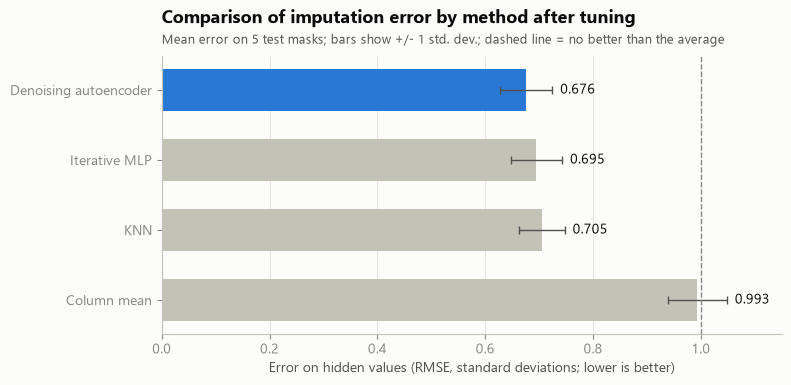

In [6]:
test_jobs = [(name, label, s) for name, (_, default, _) in IMPUTERS.items()
             for label, s in [("original", default), ("tuned", best_impute[name])]]
test_scores = Parallel(n_jobs=N_JOBS)(delayed(mask_rmse)(name, s, seed) for name, _, s in test_jobs for seed in TEST_SEEDS)
n = len(TEST_SEEDS)
rows = [{"Imputer": name, "Version": label, "RMSE": np.mean(test_scores[i * n:(i + 1) * n]), "Std": np.std(test_scores[i * n:(i + 1) * n])}
        for i, (name, label, _) in enumerate(test_jobs)]
impute_result = pd.DataFrame(rows).pivot(index="Imputer", columns="Version", values=["RMSE", "Std"])
impute_result.columns = [f"{stat}, {version}" for stat, version in impute_result.columns]
impute_result = impute_result.loc[list(IMPUTERS), ["RMSE, original", "RMSE, tuned", "Std, original", "Std, tuned"]]
print("Error on the five test masks (RMSE in standard deviations, lower is better):")
print(impute_result.round(3).to_string())

tuned = impute_result["RMSE, tuned"].sort_values(ascending=False)
best_imputer = tuned.index[-1]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(tuned.index, tuned.values, xerr=impute_result.loc[tuned.index, "Std, tuned"],
        color=[CAT[0] if name == best_imputer else AXIS for name in tuned.index], height=0.6,
        error_kw={"ecolor": INK_2, "capsize": 3, "lw": 1})
for i, name in enumerate(tuned.index):
    ax.text(tuned[name] + impute_result.loc[name, "Std, tuned"] + 0.015, i, f"{tuned[name]:.3f}", va="center", color=INK, fontsize=10)
ax.axvline(1.0, color=MUTED, lw=1, ls="--")
ax.set_xlim(0, 1.15)
ax.set_xlabel("Error on hidden values (RMSE, standard deviations; lower is better)")
ax.grid(axis="y", visible=False)
titled(ax, "Comparison of imputation error by method after tuning",
       "Mean error on 5 test masks; bars show +/- 1 std. dev.; dashed line = no better than the average")
save(fig, "tuned_imputation")

How we interpret this:

- Tuning changed the denoising autoencoder the most: its error fell from 0.682 to 0.676 with a 12 unit bottleneck and 20% of values hidden per round. KNN (20 neighbours instead of 10) and the iterative MLP (10 rounds instead of 5) chose different settings, but their error did not change at three decimals.
- After tuning, the denoising autoencoder still has the lowest error, so tuning does not change the choice of imputer.
- The gaps are small (0.676 against 0.695 for the iterative MLP and 0.705 for KNN), and the spread across the five masks (about 0.04 to 0.05) is larger than these gaps, so the autoencoder has a slight lead rather than a clear win.

## Forecasting

Each regression algorithm predicts a feature's 10 year change from a country's current features, income group and region, exactly as in `nasipadang.ipynb`. It is trained only on the 1990 to 2000 changes and tested once on the next decade.

Tuning uses `GridSearchCV` with 5 fold cross validation across countries inside the 1990 to 2000 training data, so the test decade is never seen during tuning. Each algorithm is tuned separately for each of the six features, and every grid has 14 to 16 settings. Linear regression (ordinary least squares) has no settings to tune.

In [7]:
FORECAST_SERIES = {"population": "Population", "urban": "Urban population", "gni": "GNI per capita (Atlas $)",
                   "yield": "Cereal yield (kg per hectare)", "co2": "CO2 emissions per capita (metric tons)",
                   "u5": "Under-five mortality rate (per 1,000)"}
HISTORY = {k: np.log(ts(v).rename(columns=int).pipe(lambda t: t.where(t > 0))).reindex(meta.index) for k, v in FORECAST_SERIES.items()}
income_code = pd.Series(pd.Categorical(meta["Income group"]).codes, index=meta.index)
region_code = pd.Series(pd.Categorical(meta["Region"]).codes, index=meta.index)
FORECAST_FEATURES = list(FORECAST_SERIES)
# Yearly values end at different times, so each test decade ends at the last well covered year
TEST_DECADE = {"population": 2000, "urban": 2000, "gni": 2000, "u5": 2000, "yield": 1999, "co2": 1998}


def inputs_at(year):
    return pd.DataFrame({"income": income_code, "region": region_code, **{k: HISTORY[k][year] for k in FORECAST_FEATURES}})


def new_svr():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVR(C=1.0, epsilon=0.05))

In [8]:
def pipe(model, scale=True):
    return make_pipeline(SimpleImputer(strategy="median"), *([StandardScaler()] if scale else []), model)


# name: (pipeline, settings used before tuning, grid to search); settings apply to the last pipeline step
REGRESSORS = {
    "Linear regression": (pipe(LinearRegression()), {}, {}),
    "KNN": (pipe(KNeighborsRegressor()), {"n_neighbors": 10, "weights": "distance"},
            {"n_neighbors": [3, 5, 10, 15, 20, 30, 40], "weights": ["uniform", "distance"]}),
    "Random forest": (pipe(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1), scale=False),
                      {"min_samples_leaf": 5, "max_features": 1.0, "max_depth": None},
                      {"min_samples_leaf": [1, 5, 10, 20], "max_features": [0.5, 1.0], "max_depth": [None, 10]}),
    "MLP": (pipe(MLPRegressor(solver="lbfgs", max_iter=2000, random_state=SEED)), {"hidden_layer_sizes": (16,), "alpha": 1.0},
            {"hidden_layer_sizes": [(8,), (16,), (32,), (16, 16)], "alpha": [0.01, 0.1, 1.0, 10.0]}),
    "SVR": (pipe(SVR()), {"C": 1.0, "epsilon": 0.05, "gamma": "scale"},
            {"C": [0.1, 1.0, 10.0, 100.0], "epsilon": [0.01, 0.1], "gamma": ["scale", 0.01]}),
}
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)


def last_step(model, settings):
    name = model.steps[-1][0]
    return {f"{name}__{key}": value for key, value in settings.items()}


def tune_and_test(name, k):
    model, original_settings, grid = REGRESSORS[name]
    start_year = TEST_DECADE[k]
    v = HISTORY[k]
    train_y = (v[start_year] - v[1990]) * 10 / (start_year - 1990)
    ok = train_y.notna()
    X_train, y_train = inputs_at(1990)[ok], train_y[ok]
    actual = (v[start_year + 10] - v[start_year]).dropna()
    X_test = inputs_at(start_year).loc[actual.index]

    def rmse(fitted):
        return np.sqrt(np.mean((actual - fitted.predict(X_test)) ** 2))

    original = clone(model).set_params(**last_step(model, original_settings)).fit(X_train, y_train)
    if grid:
        search = GridSearchCV(clone(model), last_step(model, grid), cv=CV, scoring="neg_root_mean_squared_error",
                              n_jobs=1).fit(X_train, y_train)
        tuned_model = search.best_estimator_
        chosen = {key.split("__", 1)[1]: value for key, value in search.best_params_.items()}
    else:
        tuned_model, chosen = original, {}
    return {"Feature": FORECAST_SERIES[k], "Algorithm": name, "No change": np.sqrt(np.mean(actual ** 2)),
            "Original": rmse(original), "Tuned": rmse(tuned_model), "Chosen settings": chosen}


forecast_rows = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(tune_and_test)(name, k) for k in TEST_DECADE for name in REGRESSORS))
FEATURE_ORDER = [FORECAST_SERIES[k] for k in TEST_DECADE]
chosen_settings = forecast_rows.pivot(index="Feature", columns="Algorithm", values="Chosen settings").loc[FEATURE_ORDER, list(REGRESSORS)]
print("Chosen settings per feature:")
for algorithm in list(REGRESSORS)[1:]:
    print(f"\n{algorithm}")
    for feature, settings in chosen_settings[algorithm].items():
        print(f"  {feature}: {settings}")

Chosen settings per feature:

KNN
  Population: {'n_neighbors': 20, 'weights': 'distance'}
  Urban population: {'n_neighbors': 40, 'weights': 'distance'}
  GNI per capita (Atlas $): {'n_neighbors': 15, 'weights': 'uniform'}
  Under-five mortality rate (per 1,000): {'n_neighbors': 30, 'weights': 'distance'}
  Cereal yield (kg per hectare): {'n_neighbors': 40, 'weights': 'distance'}
  CO2 emissions per capita (metric tons): {'n_neighbors': 15, 'weights': 'distance'}

Random forest
  Population: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5}
  Urban population: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 5}
  GNI per capita (Atlas $): {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 1}
  Under-five mortality rate (per 1,000): {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 1}
  Cereal yield (kg per hectare): {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 10}
  CO2 emissions per capita (metric tons): {'max_depth': 10, 'ma

Error on the unseen decade after tuning (RMSE of log change, lower is better):
                                        No change  Linear regression    KNN  Random forest    MLP    SVR
Feature                                                                                                 
Population                                  0.206              0.134  0.128          0.120  0.132  0.126
Urban population                            0.283              0.149  0.142          0.131  0.136  0.132
GNI per capita (Atlas $)                    0.921              0.711  0.770          0.773  0.756  0.733
Under-five mortality rate (per 1,000)       0.422              0.226  0.216          0.225  0.230  0.218
Cereal yield (kg per hectare)               0.381              0.354  0.365          0.365  0.357  0.352
CO2 emissions per capita (metric tons)      0.440              0.729  0.411          0.451  0.481  0.455

Rank per feature after tuning (1 = lowest error):
Algorithm                     

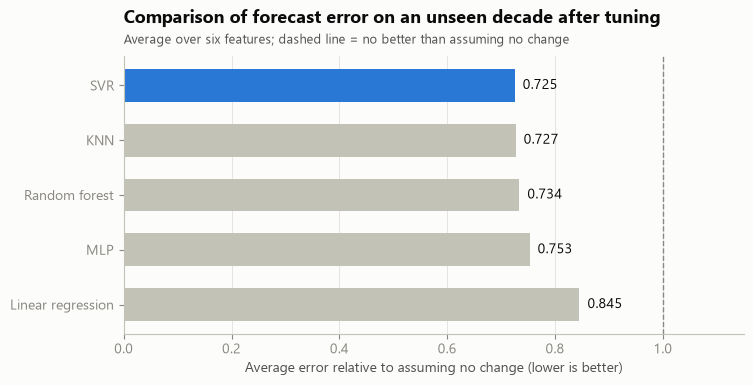

In [9]:
def table(column):
    return forecast_rows.pivot(index="Feature", columns="Algorithm", values=column).loc[FEATURE_ORDER, list(REGRESSORS)]


tuned_table, original_table = table("Tuned"), table("Original")
no_change = forecast_rows.groupby("Feature")["No change"].first().loc[FEATURE_ORDER]
print("Error on the unseen decade after tuning (RMSE of log change, lower is better):")
print(pd.concat([no_change.rename("No change"), tuned_table], axis=1).round(3).to_string())
ranks = tuned_table.rank(axis=1).astype(int)
print("\nRank per feature after tuning (1 = lowest error):")
print(ranks.to_string())
relative_tuned, relative_original = tuned_table.div(no_change, axis=0), original_table.div(no_change, axis=0)
forecast_summary = pd.DataFrame({
    "Error vs no change, original": relative_original.mean(),
    "Error vs no change, tuned": relative_tuned.mean(),
    "Average rank, tuned": ranks.mean(),
    "Worst feature vs no change, tuned": relative_tuned.max(),
}).sort_values("Error vs no change, tuned")
print("\nSummary over the six features (error relative to no change: 1.0 = no better than no change):")
print(forecast_summary.round(3).to_string())

order = forecast_summary.index[::-1]
best_forecaster = forecast_summary.index[0]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(order, forecast_summary.loc[order, "Error vs no change, tuned"],
        color=[CAT[0] if name == best_forecaster else AXIS for name in order], height=0.6)
for i, name in enumerate(order):
    value = forecast_summary.loc[name, "Error vs no change, tuned"]
    ax.text(value + 0.015, i, f"{value:.3f}", va="center", color=INK, fontsize=10)
ax.axvline(1.0, color=MUTED, lw=1, ls="--")
ax.set_xlim(0, 1.15)
ax.set_xlabel("Average error relative to assuming no change (lower is better)")
ax.grid(axis="y", visible=False)
titled(ax, "Comparison of forecast error on an unseen decade after tuning",
       "Average over six features; dashed line = no better than assuming no change")
save(fig, "tuned_forecast")

How we interpret this:

- Tuning mostly helped the algorithms whose original settings were furthest from their best: the random forest improved from 0.773 to 0.734 and the MLP from 0.772 to 0.753. SVR (0.726 to 0.725) and KNN (0.732 to 0.727) barely changed, so their original settings were already close to their best.
- After tuning, SVR has the lowest average error (0.725) and the best average rank (2.0), and it is first or second on five of the six features.
- KNN is a close second (0.727) and is the only algorithm that is never worse than assuming no change. SVR is 3% worse than no change on CO2.
- No algorithm is best on every feature: the random forest is best for population and urban population, linear regression for income, KNN for child mortality and CO2, and SVR for cereal yield.
- Linear regression has the highest average error, which is consistent with the curved patterns seen in the exploratory analysis.

SVR, KNN and the random forest are within 0.01 of each other, and this is a single test decade, so the three perform about equally well. SVR remains a reasonable choice because it has the lowest average error and the most consistent ranking, but the data does not show it to be clearly better than KNN.